In [1]:
import os
os.listdir()

['.ipynb_checkpoints',
 'customers.csv',
 'Kara Beverly-Python Capstone .ipynb',
 'orders.csv',
 'order_items.csv',
 'payments.csv',
 'products.csv',
 'README_DATA_DICTIONARY.txt',
 'returns.csv',
 'shipments.csv']

   # Python Capstone — Option A: Sales Performance & Customer Insights
   ## Step 1: Load the data
   

In [2]:
import pandas as pd

customers   = pd.read_csv('customers.csv')
products    = pd.read_csv('products.csv')
orders      = pd.read_csv('orders.csv')
order_items = pd.read_csv('order_items.csv')
payments    = pd.read_csv('payments.csv')
shipments   = pd.read_csv('shipments.csv')
returns     = pd.read_csv('returns.csv')

tables = {'customers': customers, 'products': products, 'orders': orders,
          'order_items': order_items, 'payments': payments,
          'shipments': shipments, 'returns': returns}

for name, df in tables.items():
    print(name, df.shape)

customers (5050, 13)
products (800, 9)
orders (15075, 8)
order_items (37763, 5)
payments (15000, 6)
shipments (15000, 7)
returns (1200, 6)


In [3]:
customers.head()

,customer_id,first_name,last_name,gender,age,email,phone,region_code,region_name,city,barangay,signup_date,loyalty_tier
0,CUST000001,Grace,DelosReyes,NaN,20.0,grace.delosreyes95@outlook.com,9.196001e+09,Region III,Central Luzon,Angeles,Brgy 1,2025-12-31,Bronze
1,CUST000002,Ana,Ramos,Female,35.0,ana.ramos@companymail.ph,9.026542e+09,CARAGA,Caraga,Butuan,Brgy 9,2025-02-08,Bronze
2,CUST000003,Arvin,Navarro,Male,14.0,arvin.navarrooutlook.com,9.161850e+09,NCR,Metro Manila,Pasig,Brgy 2,2023-09-10,Bronze
3,CUST000004,Kyle,Rivera,F,26.0,kyle.rivera13@outlook.com,9.752553e+09,Region III,Central Luzon,Angeles,Brgy 1,2024-11-17,NaN
4,CUST000005,Juan,Mendoza,Male,29.0,juan.mendoza@gmail.com,9.350306e+09,Region III,Central Luzon,Angeles,Brgy 9,2023-01-21,Gold


In [4]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   5050 non-null   str    
 1   first_name    5050 non-null   str    
 2   last_name     5050 non-null   str    
 3   gender        4749 non-null   str    
 4   age           4900 non-null   float64
 5   email         4943 non-null   str    
 6   phone         4903 non-null   float64
 7   region_code   5050 non-null   str    
 8   region_name   5050 non-null   str    
 9   city          5050 non-null   str    
 10  barangay      5050 non-null   str    
 11  signup_date   5050 non-null   str    
 12  loyalty_tier  4784 non-null   str    
dtypes: float64(2), str(11)
memory usage: 513.0 KB


In [5]:
for name, df in tables.items():
    print('=====', name, df.shape)
    print('Duplicate rows:', df.duplicated().sum())
    print('Missing values per column:')
    print(df.isna().sum()[df.isna().sum() > 0])
    print()

===== customers (5050, 13)
Duplicate rows: 50
Missing values per column:
gender          301
age             150
email           107
phone           147
loyalty_tier    266
dtype: int64

===== products (800, 9)
Duplicate rows: 0
Missing values per column:
stock_qty    19
dtype: int64

===== orders (15075, 8)
Duplicate rows: 75
Missing values per column:
discount_pct    758
shipping_fee    474
dtype: int64

===== order_items (37763, 5)
Duplicate rows: 262
Missing values per column:
unit_price_at_purchase    2262
dtype: int64

===== payments (15000, 6)
Duplicate rows: 0
Missing values per column:
amount_paid    878
dtype: int64

===== shipments (15000, 7)
Duplicate rows: 0
Missing values per column:
delivered_date    729
dtype: int64

===== returns (1200, 6)
Duplicate rows: 0
Missing values per column:
refunded_flag    110
refund_amount    187
dtype: int64



### Step 1 findings
- Loaded 7 CSV files. Option A uses customers, products, orders and order_items.
- orders has 75 more rows than payments/shipments (15,075 vs 15,000), matching its 75 duplicate rows.
- Main issues to clean: duplicates, missing values, inconsistent gender and category labels, mixed date formats, prices stored as text, orphan keys.

## Step 2: Data Cleaning
### 2.1 Customers

In [6]:
cleaning_log = []

def log(table, issue, action, rows_affected):
    cleaning_log.append({'table': table, 'issue': issue,
                         'action': action, 'rows_affected': rows_affected})
    print(f'Logged: {table} | {issue} | {rows_affected} rows')

In [7]:
print('Exact duplicate rows:', customers.duplicated().sum())
print('Duplicate customer_ids:', customers['customer_id'].duplicated().sum())

Exact duplicate rows: 50
Duplicate customer_ids: 50


In [8]:
before = len(customers)
customers = customers.drop_duplicates(subset='customer_id', keep='first')
removed = before - len(customers)

print('Rows before:', before, '| after:', len(customers), '| removed:', removed)
print('Duplicate customer_ids now:', customers['customer_id'].duplicated().sum())

log('customers', 'Duplicate customer_id',
    'Kept first occurrence, dropped repeats (duplicate = same customer_id)', removed)

Rows before: 5050 | after: 5000 | removed: 50
Duplicate customer_ids now: 0
Logged: customers | Duplicate customer_id | 50 rows


In [9]:
customers['gender'].value_counts(dropna=False)

gender
M          1297
F          1263
Female      721
Male        719
Unknown     587
NaN         298
female      115
Name: count, dtype: int64

In [10]:
old_gender = customers['gender'].copy()
nulls_before = old_gender.isna().sum()

gender_map = {'m': 'Male', 'male': 'Male',
              'f': 'Female', 'female': 'Female',
              'unknown': 'Unknown'}

customers['gender'] = (customers['gender']
                       .str.strip()
                       .str.lower()
                       .map(gender_map)
                       .fillna('Unknown'))

changed = (old_gender != customers['gender']).sum()
print(customers['gender'].value_counts(dropna=False))

log('customers', 'Inconsistent gender labels (M/F/Male/female...)',
    'Standardized to Male/Female/Unknown', changed - nulls_before)
log('customers', 'Null gender',
    'Filled with "Unknown" (kept customers so their orders are not lost)', nulls_before)

gender
Female     2099
Male       2016
Unknown     885
Name: count, dtype: int64
Logged: customers | Inconsistent gender labels (M/F/Male/female...) | 2675 rows
Logged: customers | Null gender | 298 rows


In [11]:
print(customers['age'].describe())
print('Negative ages:', (customers['age'] < 0).sum())
print('Missing ages:', customers['age'].isna().sum())
print()
print(customers['loyalty_tier'].value_counts(dropna=False))

count    4851.000000
mean       31.199753
std        10.587110
min        -5.000000
25%        24.000000
50%        32.000000
75%        38.000000
max        65.000000
Name: age, dtype: float64
Negative ages: 48
Missing ages: 149

loyalty_tier
Bronze      2204
Silver      1257
Gold         915
Platinum     360
NaN          264
Name: count, dtype: int64


In [12]:
import numpy as np

neg_ages = (customers['age'] < 0).sum()
customers.loc[customers['age'] < 0, 'age'] = np.nan

tier_nulls = customers['loyalty_tier'].isna().sum()
customers['loyalty_tier'] = customers['loyalty_tier'].fillna('Unknown')

print('Min age now:', customers['age'].min())
print('Missing ages now:', customers['age'].isna().sum())
print(customers['loyalty_tier'].value_counts(dropna=False))

log('customers', 'Invalid negative age', 'Set to NaN (impossible value)', neg_ages)
log('customers', 'Null age',
    'Left as NaN; age not used in revenue KPIs, so no values invented',
    customers['age'].isna().sum())
log('customers', 'Null loyalty_tier', 'Filled with "Unknown"', tier_nulls)

Min age now: 0.0
Missing ages now: 197
loyalty_tier
Bronze      2204
Silver      1257
Gold         915
Platinum     360
Unknown      264
Name: count, dtype: int64
Logged: customers | Invalid negative age | 48 rows
Logged: customers | Null age | 197 rows
Logged: customers | Null loyalty_tier | 264 rows


In [13]:
zero_ages = (customers['age'] == 0).sum()
customers.loc[customers['age'] == 0, 'age'] = np.nan
print('Min age now:', customers['age'].min())
log('customers', 'Invalid age of 0', 'Set to NaN (impossible value)', zero_ages)

Min age now: 1.0
Logged: customers | Invalid age of 0 | 1 rows


In [14]:
s = customers['signup_date']
print('YYYY-MM-DD :', s.str.match(r'^\d{4}-\d{2}-\d{2}$').sum())
print('MM/DD/YYYY :', s.str.match(r'^\d{2}/\d{2}/\d{4}$').sum())
print('DD-Mon-YYYY:', s.str.match(r'^\d{2}-[A-Za-z]{3}-\d{4}$').sum())
print('Total rows :', len(s))

YYYY-MM-DD : 3719
MM/DD/YYYY : 654
DD-Mon-YYYY: 627
Total rows : 5000


In [15]:
d1 = pd.to_datetime(s, format='%Y-%m-%d', errors='coerce')
d2 = pd.to_datetime(s, format='%m/%d/%Y', errors='coerce')
d3 = pd.to_datetime(s, format='%d-%b-%Y', errors='coerce')

customers['signup_date'] = d1.fillna(d2).fillna(d3)

print('Type now:', customers['signup_date'].dtype)
print('Could not parse:', customers['signup_date'].isna().sum())
print('Earliest:', customers['signup_date'].min(), '| Latest:', customers['signup_date'].max())

log('customers', 'Mixed signup_date formats (3 formats, stored as text)',
    'Parsed each format explicitly and combined into one datetime column', 654 + 627)

Type now: datetime64[us]
Could not parse: 0
Earliest: 2023-01-01 00:00:00 | Latest: 2026-01-31 00:00:00
Logged: customers | Mixed signup_date formats (3 formats, stored as text) | 1281 rows


In [16]:
bad_emails = (~customers['email'].str.contains('@', na=False)).sum()
log('customers', 'Missing/malformed email; phone stored as number',
    'Not used in Option A analysis; left unchanged and noted as a data limitation', bad_emails)

Logged: customers | Missing/malformed email; phone stored as number | 223 rows


In [17]:
products['category'].value_counts()

category
Beauty              94
Toys                92
Books               90
Fashion             89
Groceries           77
Home & Kitchen      76
Sports              74
Electronics         71
electronics         20
Book                20
Home and Kitchen    19
Electronics         17
Grocery             12
Elec                11
Beauty & Care       11
Toy                 11
Fashon               8
Sports & Outdoor     8
Name: count, dtype: int64

In [18]:
old_cat = products['category'].copy()

cat_map = {
    'beauty': 'Beauty', 'beauty & care': 'Beauty',
    'books': 'Books', 'book': 'Books',
    'electronics': 'Electronics', 'elec': 'Electronics',
    'fashion': 'Fashion', 'fashon': 'Fashion',
    'groceries': 'Groceries', 'grocery': 'Groceries',
    'home & kitchen': 'Home & Kitchen', 'home and kitchen': 'Home & Kitchen',
    'sports': 'Sports', 'sports & outdoor': 'Sports',
    'toys': 'Toys', 'toy': 'Toys'
}

products['category'] = products['category'].str.strip().str.lower().map(cat_map)

print(products['category'].value_counts(dropna=False))
print('Unmatched labels:', products['category'].isna().sum())

changed = (old_cat != products['category']).sum()
log('products', 'Inconsistent category labels (18 variants: casing, spaces, typos, plurals)',
    'Trimmed spaces, lowercased, mapped to 8 standard categories', changed)

category
Electronics       119
Books             110
Beauty            105
Toys              103
Fashion            97
Home & Kitchen     95
Groceries          89
Sports             82
Name: count, dtype: int64
Unmatched labels: 0
Logged: products | Inconsistent category labels (18 variants: casing, spaces, typos, plurals) | 137 rows


In [19]:
print('Type:', products['unit_price'].dtype)
print('Prices with ₱ sign:', products['unit_price'].str.contains('₱').sum())
products['unit_price'].head(10)

Type: str
Prices with ₱ sign: 68


0       64.5
1      70.39
2     ₱70.26
3      62.46
4      82.02
5     225.17
6      97.28
7    ₱124.98
8      99.25
9      40.85
Name: unit_price, dtype: str

In [20]:
peso_rows = products['unit_price'].str.contains('₱').sum()

products['unit_price'] = (products['unit_price']
                          .str.replace('₱', '', regex=False)
                          .str.replace(',', '', regex=False)
                          .str.strip())
products['unit_price'] = pd.to_numeric(products['unit_price'], errors='coerce')

print('Type now:', products['unit_price'].dtype)
print('Could not convert:', products['unit_price'].isna().sum())
print(products['unit_price'].describe())

log('products', 'unit_price stored as text with ₱ currency sign',
    'Removed ₱ and commas, converted to numeric', peso_rows)

Type now: float64
Could not convert: 0
count    800.000000
mean      93.235150
std       49.856278
min       18.430000
25%       59.345000
50%       81.385000
75%      119.042500
max      438.770000
Name: unit_price, dtype: float64
Logged: products | unit_price stored as text with ₱ currency sign | 68 rows


In [21]:
stock_nulls = products['stock_qty'].isna().sum()
print('Missing stock_qty:', stock_nulls)
print('unit_cost type:', products['unit_cost'].dtype)

log('products', 'Null stock_qty',
    'Left as NaN; stock not used in sales KPIs, and 0 would wrongly mean out of stock', stock_nulls)

Missing stock_qty: 19
unit_cost type: float64
Logged: products | Null stock_qty | 19 rows


In [22]:
print('Exact duplicate rows:', orders.duplicated().sum())
print('Duplicate order_ids:', orders['order_id'].duplicated().sum())

Exact duplicate rows: 75
Duplicate order_ids: 75


In [23]:
before = len(orders)
orders = orders.drop_duplicates(subset='order_id', keep='first')
removed = before - len(orders)

print('Rows before:', before, '| after:', len(orders), '| removed:', removed)
print('Duplicate order_ids now:', orders['order_id'].duplicated().sum())
print('Matches payments/shipments count?', len(orders) == len(payments))

log('orders', 'Duplicate order_id',
    'Kept first occurrence, dropped repeats (duplicate = same order_id)', removed)

Rows before: 15075 | after: 15000 | removed: 75
Duplicate order_ids now: 0
Matches payments/shipments count? True
Logged: orders | Duplicate order_id | 75 rows


In [24]:
orders['order_datetime'].sample(10, random_state=1)

7576     2024-08-20 14:14:00
10509      28-May-2024 03:41
4253     2025-12-30 03:03:00
5150     2025-12-02 14:45:00
506        01-Jan-2024 16:17
1622     2024-04-20 21:01:00
13684    2025-04-20 11:21:00
2145     2024-09-21 09:30:00
9296     2025-07-02 18:46:00
6900     2024-04-15 16:02:00
Name: order_datetime, dtype: str

In [25]:
s = orders['order_datetime']

d1 = pd.to_datetime(s, format='%Y-%m-%d %H:%M:%S', errors='coerce')
d2 = pd.to_datetime(s, format='%m/%d/%Y %I:%M %p', errors='coerce')
d3 = pd.to_datetime(s, format='%d-%b-%Y %H:%M', errors='coerce')

print('Format 1:', d1.notna().sum(), '| Format 2:', d2.notna().sum(), '| Format 3:', d3.notna().sum())

orders['order_datetime'] = d1.fillna(d2).fillna(d3)

print('Type now:', orders['order_datetime'].dtype)
print('Could not parse:', orders['order_datetime'].isna().sum())
print('Earliest:', orders['order_datetime'].min(), '| Latest:', orders['order_datetime'].max())

log('orders', 'Mixed order_datetime formats (3 formats incl. 12-hour AM/PM)',
    'Parsed each format explicitly and combined into one datetime column',
    d2.notna().sum() + d3.notna().sum())

Format 1: 11688 | Format 2: 1807 | Format 3: 1505
Type now: datetime64[us]
Could not parse: 0
Earliest: 2024-01-01 01:17:00 | Latest: 2026-01-31 23:36:00
Logged: orders | Mixed order_datetime formats (3 formats incl. 12-hour AM/PM) | 3312 rows


In [26]:
print('Missing discount_pct:', orders['discount_pct'].isna().sum())
print('Missing shipping_fee:', orders['shipping_fee'].isna().sum())
print(orders[['discount_pct', 'shipping_fee']].describe())

Missing discount_pct: 756
Missing shipping_fee: 470
       discount_pct  shipping_fee
count  14244.000000  14530.000000
mean       0.078469     85.746317
std        0.067251     34.926370
min        0.000000      0.000000
25%        0.016000     62.090000
50%        0.070000     85.880000
75%        0.124000    109.247500
max        0.350000    212.160000


In [27]:
disc_nulls = orders['discount_pct'].isna().sum()
fee_nulls = orders['shipping_fee'].isna().sum()
fee_median = orders['shipping_fee'].median()

orders['discount_pct'] = orders['discount_pct'].fillna(0)
orders['shipping_fee'] = orders['shipping_fee'].fillna(fee_median)

print('Median shipping fee used:', round(fee_median, 2))
print('Missing discount_pct now:', orders['discount_pct'].isna().sum())
print('Missing shipping_fee now:', orders['shipping_fee'].isna().sum())

log('orders', 'Null discount_pct', 'Filled with 0 (assume no discount applied)', disc_nulls)
log('orders', 'Null shipping_fee', f'Filled with median fee ({fee_median:.2f})', fee_nulls)

Median shipping fee used: 85.88
Missing discount_pct now: 0
Missing shipping_fee now: 0
Logged: orders | Null discount_pct | 756 rows
Logged: orders | Null shipping_fee | 470 rows


In [28]:
orphan_mask = ~orders['customer_id'].isin(customers['customer_id'])
print('Orphan orders:', orphan_mask.sum())
print(orders.loc[orphan_mask, 'customer_id'].value_counts())

Orphan orders: 43
customer_id
CUST999999    43
Name: count, dtype: int64


In [29]:
orphans = orphan_mask.sum()
orders = orders[~orphan_mask]

print('Orders now:', len(orders))
print('Orphans remaining:', (~orders['customer_id'].isin(customers['customer_id'])).sum())

log('orders', 'Orphan customer_id (all = placeholder CUST999999, not in customers)',
    'Removed; cannot be linked to a customer/region, only 0.3% of orders', orphans)

Orders now: 14957
Orphans remaining: 0
Logged: orders | Orphan customer_id (all = placeholder CUST999999, not in customers) | 43 rows


In [30]:
before = len(order_items)
order_items = order_items.drop_duplicates(subset='order_item_id', keep='first')
removed = before - len(order_items)
print('Rows before:', before, '| after:', len(order_items), '| removed:', removed)

log('order_items', 'Duplicate order_item_id',
    'Kept first occurrence, dropped repeats (duplicate = same order_item_id)', removed)

Rows before: 37763 | after: 37501 | removed: 262
Logged: order_items | Duplicate order_item_id | 262 rows


In [31]:
bad_product = ~order_items['product_id'].isin(products['product_id'])
bad_order   = ~order_items['order_id'].isin(orders['order_id'])

print('Orphan products:', bad_product.sum())
print(order_items.loc[bad_product, 'product_id'].value_counts())
print('Orphan orders:', bad_order.sum())

order_items = order_items[~(bad_product | bad_order)]
print('Rows now:', len(order_items))

log('order_items', 'Orphan product_id (placeholder PROD00000, not in products)',
    'Removed; no category/price can be linked', bad_product.sum())
log('order_items', 'Orphan order_id (order removed as duplicate/orphan)',
    'Removed so every item links to a valid order', bad_order.sum())

Orphan products: 129
product_id
PROD00000    129
Name: count, dtype: int64
Orphan orders: 111
Rows now: 37261
Logged: order_items | Orphan product_id (placeholder PROD00000, not in products) | 129 rows
Logged: order_items | Orphan order_id (order removed as duplicate/orphan) | 111 rows


In [32]:
zero_qty = (order_items['quantity'] == 0).sum()
order_items = order_items[order_items['quantity'] > 0]
print('Quantity = 0 removed:', zero_qty, '| rows now:', len(order_items))

log('order_items', 'Invalid quantity = 0',
    'Removed; a zero-quantity line is not a real sale', zero_qty)

Quantity = 0 removed: 369 | rows now: 36892
Logged: order_items | Invalid quantity = 0 | 369 rows


In [33]:
peso_items = order_items['unit_price_at_purchase'].str.contains('₱', na=False).sum()

order_items['unit_price_at_purchase'] = pd.to_numeric(
    order_items['unit_price_at_purchase']
        .str.replace('₱', '', regex=False)
        .str.replace(',', '', regex=False)
        .str.strip(),
    errors='coerce')

print('₱ prices converted:', peso_items)
print('Type now:', order_items['unit_price_at_purchase'].dtype)
print('Missing prices:', order_items['unit_price_at_purchase'].isna().sum())

log('order_items', 'unit_price_at_purchase stored as text with ₱',
    'Removed ₱ and commas, converted to numeric', peso_items)

₱ prices converted: 2965
Type now: float64
Missing prices: 2203
Logged: order_items | unit_price_at_purchase stored as text with ₱ | 2965 rows


In [34]:
price_nulls = order_items['unit_price_at_purchase'].isna().sum()

price_lookup = products.set_index('product_id')['unit_price']
order_items['unit_price_at_purchase'] = order_items['unit_price_at_purchase'].fillna(
    order_items['product_id'].map(price_lookup))

print('Missing prices now:', order_items['unit_price_at_purchase'].isna().sum())

log('order_items', 'Null unit_price_at_purchase',
    'Backfilled with product list price from products table', price_nulls)

Missing prices now: 0
Logged: order_items | Null unit_price_at_purchase | 2203 rows


In [35]:
cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df.index = cleaning_log_df.index + 1
cleaning_log_df.to_csv('cleaning_log.csv', index_label='step')

pd.set_option('display.max_colwidth', None)
cleaning_log_df

,table,issue,action,rows_affected
1,customers,Duplicate customer_id,"Kept first occurrence, dropped repeats (duplicate = same customer_id)",50
2,customers,Inconsistent gender labels (M/F/Male/female...),Standardized to Male/Female/Unknown,2675
3,customers,Null gender,"Filled with ""Unknown"" (kept customers so their orders are not lost)",298
4,customers,Invalid negative age,Set to NaN (impossible value),48
5,customers,Null age,"Left as NaN; age not used in revenue KPIs, so no values invented",197
6,customers,Null loyalty_tier,"Filled with ""Unknown""",264
7,customers,Invalid age of 0,Set to NaN (impossible value),1
8,customers,"Mixed signup_date formats (3 formats, stored as text)",Parsed each format explicitly and combined into one datetime column,1281
9,customers,Missing/malformed email; phone stored as number,Not used in Option A analysis; left unchanged and noted as a data limitation,223
10,products,"Inconsistent category labels (18 variants: casing, spaces, typos, plurals)","Trimmed spaces, lowercased, mapped to 8 standard categories",137


In [37]:
fact = (order_items
        .merge(orders, on='order_id', how='left')
        .merge(products[['product_id', 'product_name', 'brand', 'category', 'unit_cost']],
               on='product_id', how='left')
        .merge(customers[['customer_id', 'gender', 'age', 'region_name', 'city', 'loyalty_tier']],
               on='customer_id', how='left'))

fact['gross_sales'] = fact['quantity'] * fact['unit_price_at_purchase']
fact['net_sales']   = fact['gross_sales'] * (1 - fact['discount_pct'])
fact['order_month'] = fact['order_datetime'].dt.to_period('M').astype(str)

print('Fact table shape:', fact.shape)
print('Rows match order_items?', len(fact) == len(order_items))
print('Missing values:')
print(fact.isna().sum()[fact.isna().sum() > 0])
fact.head()

Fact table shape: (36892, 24)
Rows match order_items? True
Missing values:
age    1398
dtype: int64


,order_item_id,order_id,product_id,quantity,unit_price_at_purchase,customer_id,order_datetime,order_status,sales_channel,shipping_method,...,category,unit_cost,gender,age,region_name,city,loyalty_tier,gross_sales,net_sales,order_month
0,ITEM000000001,ORD0000001,PROD00513,2,120.67,CUST000839,2025-11-07 17:02:00,Cancelled,Marketplace,Standard,...,Sports,71.15,Female,23.0,Northern Mindanao,Iligan,Bronze,241.34,223.48084,2025-11
1,ITEM000000002,ORD0000002,PROD00124,2,83.58,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,Beauty,63.11,Unknown,33.0,Central Visayas,Mandaue,Gold,167.16,156.62892,2025-09
2,ITEM000000003,ORD0000002,PROD00631,2,46.96,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,Electronics,30.08,Unknown,33.0,Central Visayas,Mandaue,Gold,93.92,88.00304,2025-09
3,ITEM000000004,ORD0000002,PROD00136,1,100.59,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,Groceries,55.82,Unknown,33.0,Central Visayas,Mandaue,Gold,100.59,94.25283,2025-09
4,ITEM000000005,ORD0000002,PROD00090,1,109.18,CUST002871,2025-09-18 09:13:00,Completed,Marketplace,Express,...,Home & Kitchen,74.36,Unknown,33.0,Central Visayas,Mandaue,Gold,109.18,102.30166,2025-09


In [38]:
os.makedirs('cleaned_data', exist_ok=True)

customers.to_csv('cleaned_data/Cleaned_customers.csv', index=False)
products.to_csv('cleaned_data/Cleaned_products.csv', index=False)
orders.to_csv('cleaned_data/Cleaned_orders.csv', index=False)
order_items.to_csv('cleaned_data/Cleaned_order_items.csv', index=False)
fact.to_csv('cleaned_data/Fact_sales.csv', index=False)

os.listdir('cleaned_data')

['Cleaned_customers.csv',
 'Cleaned_orders.csv',
 'Cleaned_order_items.csv',
 'Cleaned_products.csv',
 'Fact_sales.csv']

## Step 4: KPIs

In [40]:
revenue_status = ['Completed', 'Shipped']

sales = fact[fact['order_status'].isin(revenue_status)].copy()

print('All items:', len(fact), '| Revenue items:', len(sales))
print('Statuses kept:', sales['order_status'].unique())

All items: 36892 | Revenue items: 28774
Statuses kept: <StringArray>
['Completed', 'Shipped']
Length: 2, dtype: str


In [41]:
total_revenue = sales['net_sales'].sum()
total_orders  = sales['order_id'].nunique()
aov           = total_revenue / total_orders

print(f'Total revenue:       ₱{total_revenue:,.2f}')
print(f'Total orders:        {total_orders:,}')
print(f'Average order value: ₱{aov:,.2f}')

Total revenue:       ₱5,293,430.12
Total orders:        11,601
Average order value: ₱456.29


In [42]:
monthly = (sales.groupby('order_month')
                .agg(revenue=('net_sales', 'sum'),
                     orders=('order_id', 'nunique'))
                .reset_index())
monthly['aov'] = monthly['revenue'] / monthly['orders']

print('Number of months:', len(monthly))
print('Best month: ', monthly.loc[monthly['revenue'].idxmax(), 'order_month'],
      f"₱{monthly['revenue'].max():,.0f}")
print('Worst month:', monthly.loc[monthly['revenue'].idxmin(), 'order_month'],
      f"₱{monthly['revenue'].min():,.0f}")
monthly.round(2)

Number of months: 25
Best month:  2025-04 ₱235,308
Worst month: 2025-02 ₱185,420


,order_month,revenue,orders,aov
0,2024-01,213783.75,462,462.74
1,2024-02,195654.41,423,462.54
2,2024-03,216476.09,477,453.83
3,2024-04,216524.92,468,462.66
4,2024-05,228237.72,470,485.61
5,2024-06,216187.95,490,441.20
6,2024-07,227789.61,494,461.11
7,2024-08,208708.84,482,433.01
8,2024-09,201401.07,463,434.99
9,2024-10,226830.01,481,471.58


### Monthly trend findings
- Revenue is broadly flat: monthly sales stay between about₱185K and about₱235K across 25 months.
- 2025 revenue (about ₱2.52M) was about 2% lower than 2024 (about₱2.57M).
- Jan–Feb 2025 were the weakest months (about₱185K); April 2025 was the best (about₱235K).
- AOV is stable (about₱435–₱485), so revenue changes come from the number of orders, not order size.

In [43]:
top_products = (sales.groupby(['product_name', 'category'])
                     .agg(revenue=('net_sales', 'sum'),
                          units_sold=('quantity', 'sum'))
                     .sort_values('revenue', ascending=False)
                     .head(10)
                     .reset_index())

top10_share = top_products['revenue'].sum() / total_revenue
print(f'Top 10 products = {top10_share:.1%} of total revenue')
top_products.round(2)

Top 10 products = 4.0% of total revenue


,product_name,category,revenue,units_sold
0,KidJoy Toys 607,Toys,27351.61,68
1,FreshCart Fashion 562,Fashion,23193.47,65
2,GlowCo Fashion 931,Fashion,22299.09,115
3,FitPro Home 691,Home & Kitchen,21811.31,78
4,HomeEase Sports 288,Sports,20806.34,98
5,KidJoy Beauty 543,Beauty,20319.66,138
6,GlowCo Beauty 566,Beauty,20108.62,105
7,BookNest Toys 264,Toys,19756.22,81
8,UrbanWear Groceries 328,Groceries,18690.92,96
9,HomeEase Groceries 174,Groceries,18277.23,105


### Top 10 products findings
- The top 10 products make up only 4.0% of total revenue, so sales are spread across many products rather than a few bestsellers.
- The top 10 come from 6 different categories (Toys, Fashion, Beauty, Groceries, Home & Kitchen, Sports).
- KidJoy Toys 607 earns the most revenue (about ₱27,352) from only 68 units, while KidJoy Beauty 543 sold the most units (138) but ranks 6th, so price matters as much as volume.

In [44]:
by_category = (sales.groupby('category')
                    .agg(revenue=('net_sales', 'sum'),
                         orders=('order_id', 'nunique'),
                         units_sold=('quantity', 'sum'))
                    .sort_values('revenue', ascending=False)
                    .reset_index())
by_category['share_%'] = (by_category['revenue'] / total_revenue * 100).round(1)

by_category.round(2)

,category,revenue,orders,units_sold,share_%
0,Toys,738320.75,3308,8000,13.9
1,Electronics,719343.29,3610,8875,13.6
2,Fashion,683244.77,3113,7556,12.9
3,Beauty,678927.49,3308,8185,12.8
4,Home & Kitchen,676370.38,3154,7599,12.8
5,Books,617336.90,3416,8193,11.7
6,Groceries,610682.53,2917,6905,11.5
7,Sports,569204.01,2636,6140,10.8


### Revenue by category findings
- Revenue is fairly balanced across the 8 categories (10.8% to 13.9% each).
- Toys is the top category (about ₱738K, 13.9%); Sports is the lowest (about ₱569K, 10.8%).
- Electronics has the most orders (3,610) and units sold (8,875) but ranks 2nd in revenue, so its items are lower priced on average.
- Standardizing category labels mattered: Electronics was originally split across 4 different labels.

In [45]:
by_region = (sales.groupby('region_name')
                  .agg(revenue=('net_sales', 'sum'),
                       orders=('order_id', 'nunique'),
                       customers=('customer_id', 'nunique'))
                  .sort_values('revenue', ascending=False)
                  .reset_index())
by_region['share_%'] = (by_region['revenue'] / total_revenue * 100).round(1)
by_region['aov'] = by_region['revenue'] / by_region['orders']

by_region.round(2)

,region_name,revenue,orders,customers,share_%,aov
0,Central Luzon,926983.03,2021,763,17.5,458.68
1,Central Visayas,905345.09,1981,768,17.1,457.01
2,Metro Manila,886292.54,1938,768,16.7,457.32
3,Caraga,882482.80,1945,741,16.7,453.72
4,Northern Mindanao,872902.78,1870,724,16.5,466.79
5,CALABARZON,819423.88,1846,755,15.5,443.89


In [46]:
by_city = (sales.groupby(['region_name', 'city'])['net_sales']
                .sum()
                .sort_values(ascending=False)
                .head(10)
                .reset_index(name='revenue'))
by_city.round(2)

,region_name,city,revenue
0,Central Luzon,Olongapo,340940.00
1,Northern Mindanao,Iligan,319309.98
2,Central Luzon,San Fernando,312113.30
3,Northern Mindanao,Cagayan de Oro,280065.48
4,Central Luzon,Angeles,273929.73
5,Northern Mindanao,Valencia,273527.32
6,Caraga,Tandag,263054.59
7,Central Visayas,Cebu City,243054.69
8,Central Visayas,Lapu-Lapu,232032.59
9,Central Visayas,Tagbilaran,215679.70


### Revenue by region and city findings
- Revenue is evenly spread across the 6 regions (15.5% to 17.5% each).
- Central Luzon is the top region (about ₱927K, 17.5%); CALABARZON is the lowest (about ₱819K, 15.5%) and also has the lowest AOV (₱443.89).
- Metro Manila ranks only 3rd, and none of its cities appear in the top 10, because its revenue is spread across 5 cities.
- Olongapo (Central Luzon) is the top city (about ₱341K), followed by Iligan (Northern Mindanao, about ₱319K).
- Northern Mindanao has the highest AOV (₱466.79) despite having the fewest customers.

In [47]:
customer_summary = (sales.groupby('customer_id')
                         .agg(orders=('order_id', 'nunique'),
                              total_spend=('net_sales', 'sum'))
                         .reset_index())

customer_summary['customer_type'] = customer_summary['orders'].apply(
    lambda n: 'Repeat' if n > 1 else 'New (one-time)')

repeat_vs_new = (customer_summary.groupby('customer_type')
                                 .agg(customers=('customer_id', 'count'),
                                      revenue=('total_spend', 'sum'),
                                      avg_spend=('total_spend', 'mean'),
                                      avg_orders=('orders', 'mean'))
                                 .reset_index())
repeat_vs_new['customers_%'] = (repeat_vs_new['customers'] / repeat_vs_new['customers'].sum() * 100).round(1)
repeat_vs_new['revenue_%'] = (repeat_vs_new['revenue'] / total_revenue * 100).round(1)

repeat_vs_new.round(2)

,customer_type,customers,revenue,avg_spend,avg_orders,customers_%,revenue_%
0,New (one-time),1141,511989.10,448.72,1.0,25.2,9.7
1,Repeat,3378,4781441.02,1415.47,3.1,74.8,90.3


### Repeat vs new customers findings
- Definition: repeat = more than 1 order; new (one-time) = exactly 1 order (Completed/Shipped only).
- 74.8% of customers (3,378) are repeat customers, and they generate 90.3% of revenue.
- Repeat customers spend about ₱1,415 on average over about 3.1 orders, roughly 3x a one-time customer (about ₱449).
- The 25-month data window gives customers more time to reorder, which partly explains the high repeat rate.

## Step 5: Visualizations

In [48]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#52514e'

plt.rcParams.update({
    'figure.figsize': (10, 5.5), 'font.size': 11,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': GRAY,
    'xtick.color': GRAY, 'ytick.color': GRAY,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'axes.axisbelow': True
})

peso_k = mticker.FuncFormatter(lambda x, pos: f'₱{x/1000:,.0f}K')

os.makedirs('charts', exist_ok=True)
print('Chart setup ready')

Chart setup ready


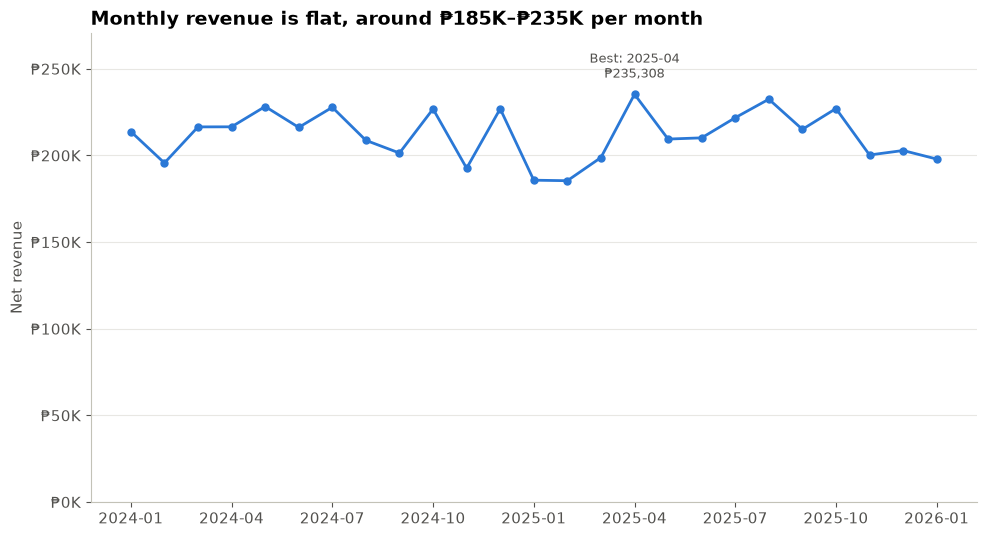

In [49]:
fig, ax = plt.subplots()

ax.plot(monthly['order_month'], monthly['revenue'],
        color=BLUE, linewidth=2, marker='o', markersize=5)

ax.set_title('Monthly revenue is flat, around ₱185K–₱235K per month')
ax.set_ylabel('Net revenue')
ax.yaxis.set_major_formatter(peso_k)
ax.set_ylim(0, monthly['revenue'].max() * 1.15)
ax.set_xticks(monthly['order_month'][::3])
ax.grid(axis='x', visible=False)

best = monthly.loc[monthly['revenue'].idxmax()]
ax.annotate(f"Best: {best['order_month']}\n₱{best['revenue']:,.0f}",
            xy=(best['order_month'], best['revenue']),
            xytext=(0, 12), textcoords='offset points',
            ha='center', fontsize=9, color=GRAY)

plt.tight_layout()
plt.savefig('charts/01_monthly_revenue.png', dpi=150)
plt.show()

**Interpretation:** Monthly revenue stays between about ₱185K and ₱235K with no clear upward or downward trend. The weakest period was Jan–Feb 2025, and the business recovered to its best month in April 2025.

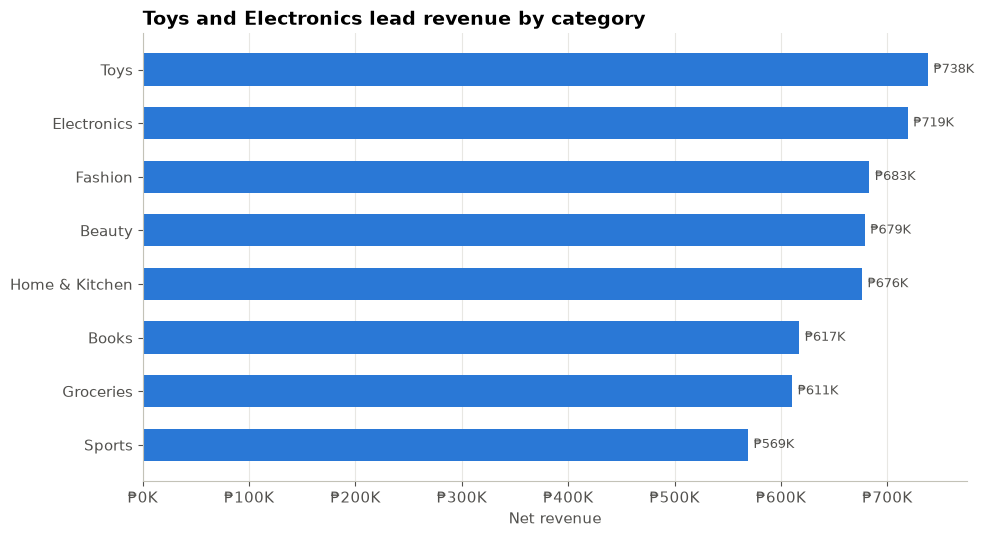

In [50]:
fig, ax = plt.subplots()

d = by_category.sort_values('revenue')
bars = ax.barh(d['category'], d['revenue'], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f'₱{v/1000:,.0f}K' for v in d['revenue']],
             padding=4, fontsize=9, color=GRAY)

ax.set_title('Toys and Electronics lead revenue by category')
ax.set_xlabel('Net revenue')
ax.xaxis.set_major_formatter(peso_k)
ax.grid(axis='y', visible=False)

plt.tight_layout()
plt.savefig('charts/02_revenue_by_category.png', dpi=150)
plt.show()

**Interpretation:** All 8 categories earn between ₱569K and ₱738K, so no single category dominates. Toys leads and Sports trails by about ₱169K.

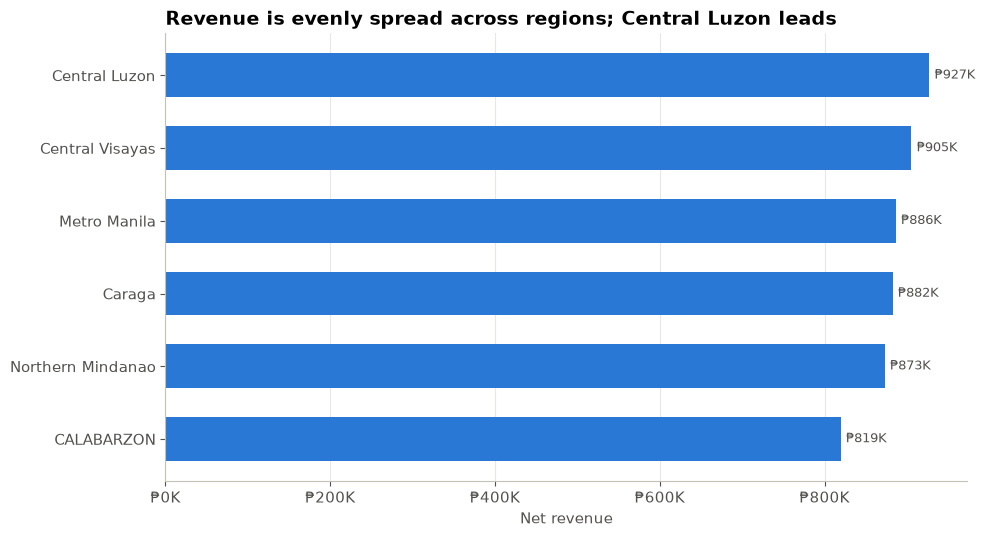

In [51]:
fig, ax = plt.subplots()

d = by_region.sort_values('revenue')
bars = ax.barh(d['region_name'], d['revenue'], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f'₱{v/1000:,.0f}K' for v in d['revenue']],
             padding=4, fontsize=9, color=GRAY)

ax.set_title('Revenue is evenly spread across regions; Central Luzon leads')
ax.set_xlabel('Net revenue')
ax.xaxis.set_major_formatter(peso_k)
ax.grid(axis='y', visible=False)

plt.tight_layout()
plt.savefig('charts/03_revenue_by_region.png', dpi=150)
plt.show()

**Interpretation:** All 6 regions contribute between 15.5% and 17.5% of revenue. Central Luzon leads, Metro Manila ranks only 3rd, and CALABARZON is the lowest.

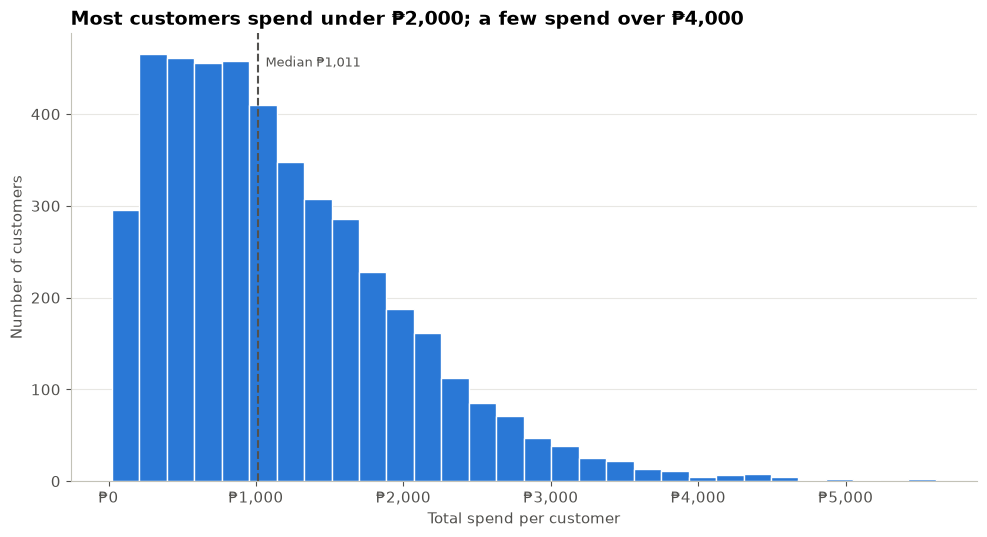

In [52]:
fig, ax = plt.subplots()

ax.hist(customer_summary['total_spend'], bins=30,
        color=BLUE, edgecolor='white', linewidth=1)

med = customer_summary['total_spend'].median()
ax.axvline(med, color=GRAY, linestyle='--', linewidth=1.5)
ax.text(med, ax.get_ylim()[1] * 0.95, f'  Median ₱{med:,.0f}',
        color=GRAY, fontsize=9, va='top')

ax.set_title('Most customers spend under ₱2,000; a few spend over ₱4,000')
ax.set_xlabel('Total spend per customer')
ax.set_ylabel('Number of customers')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'₱{x:,.0f}'))
ax.grid(axis='x', visible=False)

plt.tight_layout()
plt.savefig('charts/04_customer_spend_distribution.png', dpi=150)
plt.show()

**Interpretation:** Customer spend is right-skewed: half of customers spend less than ₱1,011 in total, while a small group of high-value, mostly repeat customers spend ₱3,000 to ₱5,600. These high spenders are the store's most valuable segment.

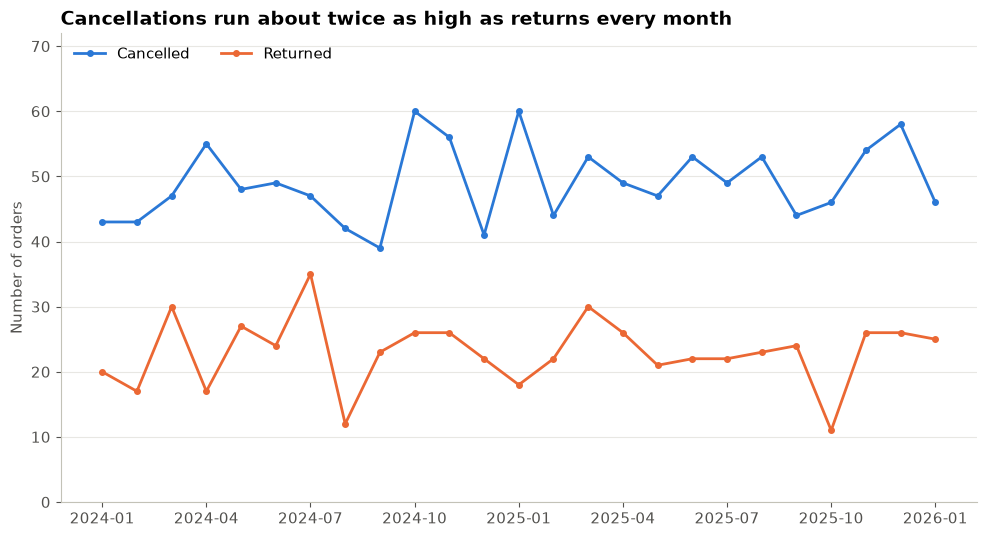

order_status
Cancelled    49.0
Returned     23.0
dtype: float64


In [53]:
status_trend = (fact[fact['order_status'].isin(['Cancelled', 'Returned'])]
                .groupby(['order_month', 'order_status'])['order_id']
                .nunique()
                .unstack())

fig, ax = plt.subplots()

ax.plot(status_trend.index, status_trend['Cancelled'],
        color=BLUE, linewidth=2, marker='o', markersize=4, label='Cancelled')
ax.plot(status_trend.index, status_trend['Returned'],
        color=ORANGE, linewidth=2, marker='o', markersize=4, label='Returned')

ax.set_title('Cancellations run about twice as high as returns every month')
ax.set_ylabel('Number of orders')
ax.set_ylim(0, status_trend.values.max() * 1.2)
ax.set_xticks(status_trend.index[::3])
ax.grid(axis='x', visible=False)
ax.legend(frameon=False, loc='upper left', ncols=2)

plt.tight_layout()
plt.savefig('charts/05_cancellations_returns_trend.png', dpi=150)
plt.show()

print(status_trend.mean().round(1))

**Interpretation:** About 49 orders are cancelled and 23 returned each month (8.2% and 3.9% of all orders), with no sign of improvement over time. Together they represent about ₱818K in lost sales, roughly 15% of realized revenue, making cancellations the biggest opportunity to recover revenue.

## Step 6: Dashboard 

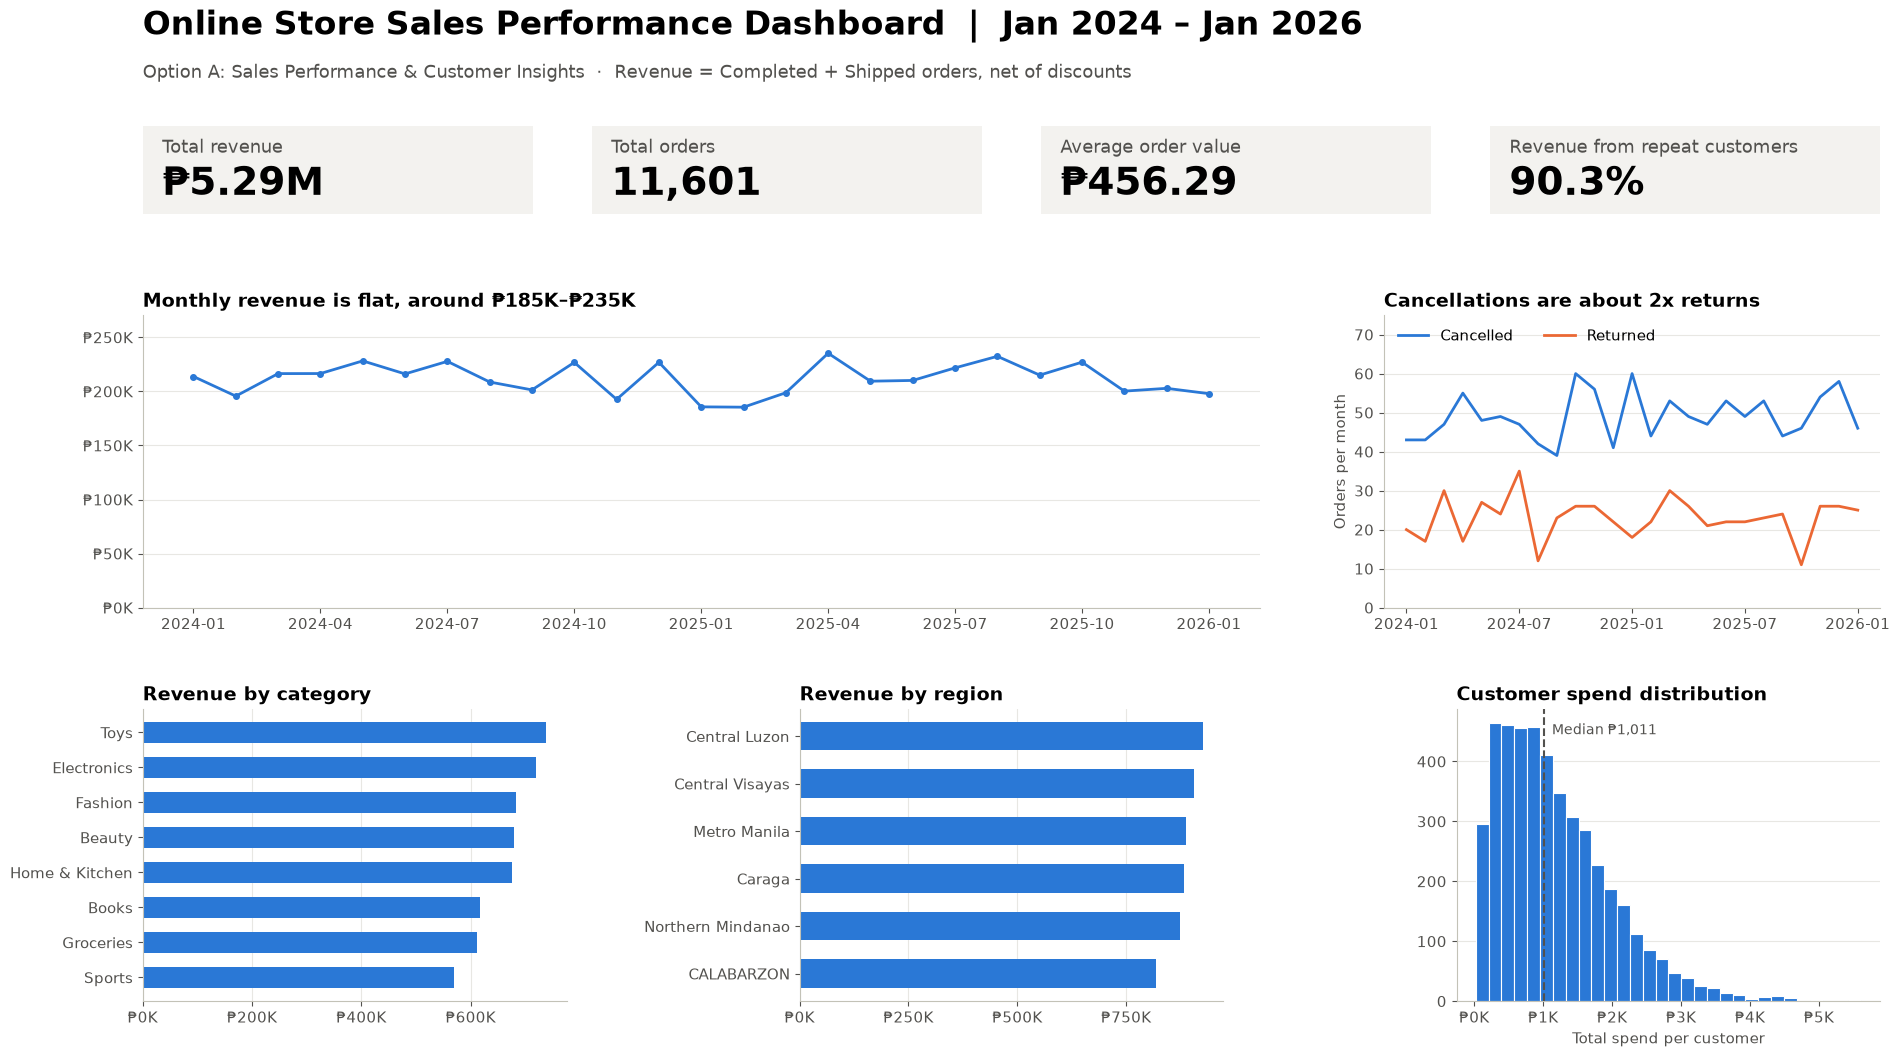

In [54]:
fig = plt.figure(figsize=(19.2, 10.8), dpi=100)
gs = fig.add_gridspec(3, 1, height_ratios=[0.6, 2, 2],
                      left=0.075, right=0.98, top=0.87, bottom=0.06, hspace=0.45)
row1 = gs[0].subgridspec(1, 4, wspace=0.15)
row2 = gs[1].subgridspec(1, 3, wspace=0.25)
row3 = gs[2].subgridspec(1, 3, wspace=0.55)

fig.text(0.075, 0.955, 'Online Store Sales Performance Dashboard  |  Jan 2024 – Jan 2026',
         fontsize=24, fontweight='bold')
fig.text(0.075, 0.915, 'Option A: Sales Performance & Customer Insights  ·  Revenue = Completed + Shipped orders, net of discounts',
         fontsize=13, color=GRAY)

# --- Row 1: KPI cards
repeat_share = repeat_vs_new.loc[repeat_vs_new['customer_type'] == 'Repeat', 'revenue_%'].iloc[0]
kpis = [('Total revenue', f'₱{total_revenue/1e6:,.2f}M'),
        ('Total orders', f'{total_orders:,}'),
        ('Average order value', f'₱{aov:,.2f}'),
        ('Revenue from repeat customers', f'{repeat_share:.1f}%')]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(row1[0, i])
    ax.set_facecolor('#f3f2ef')
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.text(0.05, 0.70, label, fontsize=13, color=GRAY, transform=ax.transAxes)
    ax.text(0.05, 0.22, value, fontsize=28, fontweight='bold', transform=ax.transAxes)

# --- Row 2: monthly trend (wide) + cancellations/returns
ax = fig.add_subplot(row2[0, 0:2])
ax.plot(monthly['order_month'], monthly['revenue'], color=BLUE, linewidth=2, marker='o', markersize=4)
ax.set_title('Monthly revenue is flat, around ₱185K–₱235K')
ax.yaxis.set_major_formatter(peso_k)
ax.set_ylim(0, monthly['revenue'].max() * 1.15)
ax.set_xticks(monthly['order_month'][::3])
ax.grid(axis='x', visible=False)

ax = fig.add_subplot(row2[0, 2])
ax.plot(status_trend.index, status_trend['Cancelled'], color=BLUE, linewidth=2, label='Cancelled')
ax.plot(status_trend.index, status_trend['Returned'], color=ORANGE, linewidth=2, label='Returned')
ax.set_title('Cancellations are about 2x returns')
ax.set_ylabel('Orders per month')
ax.set_ylim(0, status_trend.values.max() * 1.25)
ax.set_xticks(status_trend.index[::6])
ax.grid(axis='x', visible=False)
ax.legend(frameon=False, loc='upper left', ncols=2)

# --- Row 3: category, region, customer spend
ax = fig.add_subplot(row3[0, 0])
d = by_category.sort_values('revenue')
ax.barh(d['category'], d['revenue'], color=BLUE, height=0.6)
ax.set_title('Revenue by category')
ax.xaxis.set_major_formatter(peso_k)
ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
ax.grid(axis='y', visible=False)

ax = fig.add_subplot(row3[0, 1])
d = by_region.sort_values('revenue')
ax.barh(d['region_name'], d['revenue'], color=BLUE, height=0.6)
ax.set_title('Revenue by region')
ax.xaxis.set_major_formatter(peso_k)
ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
ax.grid(axis='y', visible=False)

ax = fig.add_subplot(row3[0, 2])
ax.hist(customer_summary['total_spend'], bins=30, color=BLUE, edgecolor='white', linewidth=0.8)
med = customer_summary['total_spend'].median()
ax.axvline(med, color=GRAY, linestyle='--', linewidth=1.5)
ax.text(med, ax.get_ylim()[1] * 0.95, f'  Median ₱{med:,.0f}', color=GRAY, fontsize=10, va='top')
ax.set_title('Customer spend distribution')
ax.set_xlabel('Total spend per customer')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'₱{x/1000:,.0f}K'))
ax.grid(axis='x', visible=False)

plt.savefig('charts/00_dashboard_1920x1080.png', dpi=100)
plt.show()

In [55]:
   from PIL import Image
   print(Image.open('charts/00_dashboard_1920x1080.png').size)

(1920, 1080)
